# Phase 5 — Pair Feature Engineering

**Purpose.** Turn every candidate pair from Phase 4 into a numeric feature vector, check that each feature carries signal, and test which
**feature groups** actually improve a classifier. Phase 4 showed the hard negatives are near-duplicates (same name, different house number,
extra words like "Partners"), so beyond plain similarity scores this phase adds house-number, unmatched-token (IDF-weighted), legal-suffix and
within-query relative features.

**Discipline.**
- Features are **label-free**: computed from raw text, retrieval scores and unlabelled S2/S3 statistics only. The same function is reused unchanged for val and test.
- Token-frequency tables and TF-IDF vocabularies are fitted on an **unlabelled** S2/S3 pool sample (no train labels involved).
- The group ablation uses a **hold-out of train queries** (20 % of the 24 k train entities). The val set is featurized but **not touched** by any analysis here.
- Thresholds picked in this notebook are for development only (optimistic); real tuning happens in Phase 8 and evaluation in Phase 9.

**Sections:** 1 Load → 2 Statistics + features → 3 Sanity → 4 Univariate separation → 5 Redundancy → 6 Feature-group ablation → 7 Errors → 8 Save

In [1]:
import os, sys, json, time, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.ensemble import HistGradientBoostingClassifier

warnings.filterwarnings("ignore")
sys.path.insert(0, os.getcwd())
import pair_features as PF
import eval_utils as EU

ROOT = "../../../"
INTERIM = ROOT + "dataset/interim"
CFG = json.load(open("retrieval_config.json"))
SEED = 42
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)
print("features defined:", len(PF.ALL_FEATURES), "|", {k: len(v) for k, v in PF.GROUPS.items()})

features defined: 77 | {'name_basic': 13, 'name_structural': 19, 'addr_basic': 9, 'addr_numbers': 7, 'retrieval': 8, 'relative': 21}


## 1. Load Phase 4 candidates and truth counts

In [2]:
ctr = pd.read_pickle(INTERIM + "/candidates_train.pkl")
cva = pd.read_pickle(INTERIM + "/candidates_val.pkl")
P4 = pickle.load(open(INTERIM + "/phase4_truth_and_queries.pkl", "rb"))
truth, queries = P4["truth"], P4["queries"]
ntrue = {s: truth[s].groupby("s1_id").size() for s in ["train", "val"]}       # true matches per entity (incl. ones retrieval missed)
ents = {s: queries[queries["split"] == s]["s1_id"].tolist() for s in ["train", "val"]}
print(f"train: {len(ctr):,} pairs / {len(ents['train']):,} entities | val: {len(cva):,} pairs / {len(ents['val']):,} entities")
assert set(ctr["s1_id"]).isdisjoint(set(cva["s1_id"]))

train: 910,783 pairs / 24,000 entities | val: 227,888 pairs / 6,000 entities


## 2. Unlabelled statistics, then features
Document frequencies (for IDF-weighted overlap) and TF-IDF vocabularies come from the Phase 3 unlabelled S2/S3 pool sample.
Features are computed in 2 worker processes (~6–8 min for the train table).

In [3]:
STATS_P = INTERIM + "/feature_stats.pkl"
if os.path.exists(STATS_P):
    stats = pickle.load(open(STATS_P, "rb")); print("loaded cached stats")
else:
    pool = pickle.load(open(INTERIM + "/phase3_pool.pkl", "rb"))["pool"]
    t0 = time.time(); stats = PF.build_stats(pool["name_n"].tolist(), pool["addr_n"].tolist(), fit_n=500_000)
    pickle.dump(stats, open(STATS_P, "wb")); print(f"stats built from {stats['N']:,} unlabelled pool records in {time.time()-t0:.0f}s")

FT_P, FV_P = INTERIM + "/features_train.pkl", INTERIM + "/features_val.pkl"
def get_features(df, path, name):
    if os.path.exists(path):
        return pd.read_pickle(path)
    t0 = time.time(); print(f"computing {name} features...")
    F = PF.compute_features(df.drop(columns=["label"]), stats, CFG)          # label column is never passed in
    F.to_pickle(path); print(f"{name}: {F.shape} in {(time.time()-t0)/60:.1f} min"); return F
Ftr = get_features(ctr, FT_P, "train")
Fva = get_features(cva, FV_P, "val")
assert len(Ftr) == len(ctr) and len(Fva) == len(cva)

loaded cached stats


## 3. Sanity checks
Missing-value rate per feature (structural NaNs are expected: address features when the candidate has no address, number features when a side has no digits),
constant features, value ranges, and an explicit leakage check.

In [4]:
nan = Ftr.isna().mean().round(3)
const = [c for c in Ftr.columns if Ftr[c].nunique(dropna=True) <= 1]
print("features with >5% NaN (structural):"); print(nan[nan > 0.05].sort_values(ascending=False).to_string())
print("constant features:", const or "none")
print("any inf:", bool(np.isinf(Ftr.values).any()))
assert "label" not in Ftr.columns
print("val feature distributions match train? max |mean diff|/std over features: %.3f" %
      float(((Ftr.mean() - Fva.mean()).abs() / (Ftr.std() + 1e-9)).max()))

features with >5% NaN (structural):
name_score            0.475
name_rank             0.475
addr_score            0.473
addr_rank             0.473
a_first_num_eq        0.157
a_num_conflict        0.157
a_num_shared          0.157
a_num_jacc            0.157
a_num_min_edit        0.157
a_num_jacc__rank      0.157
a_num_jacc__dmax      0.157
a_num_jacc__margin    0.157
constant features: none
any inf: False


val feature distributions match train? max |mean diff|/std over features: 0.016


## 4. Univariate separation
AUC of each single feature for match-vs-non-match on the train candidates (computed on the rows where the feature exists; `coverage` shows how many).
`AUC` is folded to ≥ 0.5; `sign` says whether higher values mean "match".

,auc,sign,coverage,group
feature,,,,
a_idf_jacc,0.9406,1,0.9784,addr_basic
a_tfidf_cos,0.9348,1,0.9784,addr_basic
a_jacc,0.9290,1,0.9784,addr_basic
a_tfidf_cos__margin,0.9271,1,0.9784,relative
a_tfidf_cos__dmax,0.9268,1,0.9784,relative
a_tset,0.9258,1,0.9784,addr_basic
a_tfidf_cos__rank,0.9253,-1,0.9784,relative
a_tsort,0.9217,1,0.9784,addr_basic
a_tsort__margin,0.9181,1,0.9784,relative


best feature per group:


,auc,sign,coverage,group
feature,,,,
a_idf_jacc,0.9406,1,0.9784,addr_basic
a_num_jacc,0.9172,1,0.8428,addr_numbers
n_ratio,0.8623,1,1.0000,name_basic
n_soft_c,0.8438,1,1.0000,name_structural
a_tfidf_cos__margin,0.9271,1,0.9784,relative
addr_score,0.9120,1,0.5270,retrieval


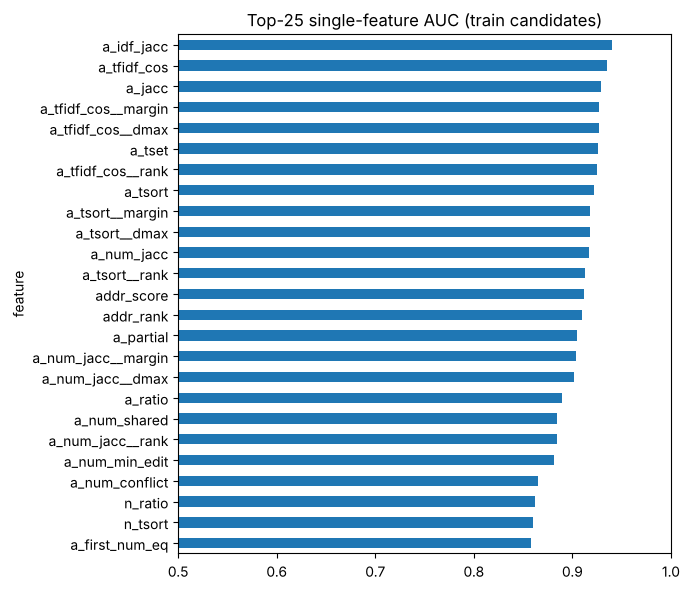

In [5]:
y = ctr["label"].values
rows = []
for c in Ftr.columns:
    m = Ftr[c].notna().values
    if m.sum() < 1000 or len(np.unique(y[m])) < 2 or Ftr.loc[m, c].nunique() < 2:
        rows.append(dict(feature=c, auc=np.nan, sign=0, coverage=m.mean())); continue
    a = roc_auc_score(y[m], Ftr.loc[m, c].values)
    rows.append(dict(feature=c, auc=max(a, 1 - a), sign=1 if a >= 0.5 else -1, coverage=m.mean()))
uni = pd.DataFrame(rows).set_index("feature")
uni["group"] = [next(g for g, v in PF.GROUPS.items() if c in v) for c in uni.index]
display(uni.sort_values("auc", ascending=False).head(20).round(4))
print("best feature per group:"); display(uni.groupby("group")["auc"].agg(["max", "idxmax"]) if False else uni.loc[uni.groupby("group")["auc"].idxmax()].round(4))
fig, ax = plt.subplots(figsize=(7, 6))
uni.sort_values("auc").dropna().tail(25)["auc"].plot.barh(ax=ax); ax.set_xlim(0.5, 1); ax.set_title("Top-25 single-feature AUC (train candidates)")
plt.tight_layout(); plt.show()

## 5. Redundancy
Spearman correlation on a 100 k-row sample; pairs with |ρ| > 0.97 are near-duplicates (kept for tree models, but flagged — a candidate for pruning if the model is slow).

In [6]:
cs = Ftr.sample(100_000, random_state=SEED).corr(method="spearman")
pairs = [(a, b, cs.loc[a, b]) for i, a in enumerate(cs.columns) for b in cs.columns[i + 1:] if abs(cs.loc[a, b]) > 0.97]
print(f"{len(pairs)} feature pairs with |rho| > 0.97:")
for a, b, r in sorted(pairs, key=lambda x: -abs(x[2]))[:15]: print(f"  {a:18s} ~ {b:18s} {r:+.3f}")

20 feature pairs with |rho| > 0.97:
  a_tsort__dmax      ~ a_tsort__margin    +1.000
  a_tfidf_cos__dmax  ~ a_tfidf_cos__margin +1.000
  n_jw__dmax         ~ n_jw__margin       +1.000
  n_tfidf_cos__dmax  ~ n_tfidf_cos__margin +1.000
  n_soft_min__dmax   ~ n_soft_min__margin +1.000
  n_idf_jacc__dmax   ~ n_idf_jacc__margin +1.000
  a_num_jacc__dmax   ~ a_num_jacc__margin +1.000
  a_jacc             ~ a_idf_jacc         +0.992
  a_num_shared       ~ a_num_conflict     -0.992
  n_jw               ~ n_jw__dmax         +0.987
  n_jw               ~ n_jw__margin       +0.987
  a_num_jacc         ~ a_num_conflict     -0.985
  a_num_jacc         ~ a_num_shared       +0.981
  n_jacc             ~ n_idf_jacc         +0.981
  n_tfidf_cos        ~ n_tfidf_cos__dmax  +0.978


## 6. Feature-group ablation (train hold-out)

80 % of **train queries** fit a gradient-boosted classifier, the other 20 % evaluate it. For each feature set we report
**PR-AUC** (stable, all pairs) and the **best-threshold macro F0.5** on the hold-out (optimistic: the threshold is tuned on the same hold-out; ~4.8 k entities so differences < 0.003 are noise).

- **Cumulative:** groups added in order name_basic → name_structural → addr_basic → addr_numbers → retrieval → relative.
- **Leave-one-group-out:** full set minus one group. A group that costs ≥ 0.002 PR-AUC when removed is "needed on its own"; otherwise it is "substitutable" —
  *another group may carry the same signal*, so section 6b compares the substitutable groups jointly before anything is dropped.

fit pairs 728,784 | hold-out pairs 181,999 (4,800 entities)
cumulative +name_basic       PR-AUC 0.6790  F0.5 0.6371  (8s)
cumulative +name_structural  PR-AUC 0.7411  F0.5 0.6736  (16s)
cumulative +addr_basic       PR-AUC 0.9839  F0.5 0.9313  (19s)
cumulative +addr_numbers     PR-AUC 0.9875  F0.5 0.9429  (18s)
cumulative +retrieval        PR-AUC 0.9908  F0.5 0.9459  (23s)
cumulative +relative         PR-AUC 0.9905  F0.5 0.9452  (27s)


,n_features,pr_auc,macro_f05,thr,secs
step,,,,,
+ name_basic,13,0.6790,0.6371,0.3,8.4842
+ name_structural,32,0.7411,0.6736,0.3,15.5817
+ addr_basic,41,0.9839,0.9313,0.6,19.1853
+ addr_numbers,48,0.9875,0.9429,0.6,17.7459
+ retrieval,56,0.9908,0.9459,0.7,23.0582
+ relative,77,0.9905,0.9452,0.7,26.5481


without name_basic       PR-AUC 0.9917 (+0.0012)  F0.5 0.9428 (-0.0024)
without name_structural  PR-AUC 0.9854 (-0.0051)  F0.5 0.9383 (-0.0069)
without addr_basic       PR-AUC 0.9920 (+0.0015)  F0.5 0.9446 (-0.0006)
without addr_numbers     PR-AUC 0.9853 (-0.0052)  F0.5 0.9371 (-0.0081)
without retrieval        PR-AUC 0.9936 (+0.0031)  F0.5 0.9465 (+0.0013)
without relative         PR-AUC 0.9908 (+0.0003)  F0.5 0.9459 (+0.0007)


,pr_auc_without,d_pr_auc,f05_without,d_f05,verdict
group,,,,,
name_basic,0.9917,0.0012,0.9428,-0.0024,substitutable (see 6b)
name_structural,0.9854,-0.0051,0.9383,-0.0069,needed on its own
addr_basic,0.9920,0.0015,0.9446,-0.0006,substitutable (see 6b)
addr_numbers,0.9853,-0.0052,0.9371,-0.0081,needed on its own
retrieval,0.9936,0.0031,0.9465,0.0013,substitutable (see 6b)
relative,0.9908,0.0003,0.9459,0.0007,substitutable (see 6b)


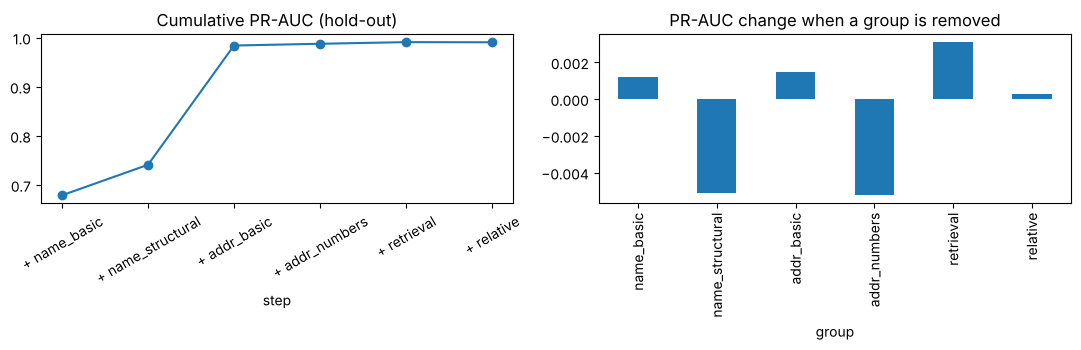

In [7]:
rng = np.random.default_rng(SEED)
tr_ent = np.array(ents["train"]); hold = set(rng.choice(tr_ent, int(0.2 * len(tr_ent)), replace=False))
is_hold = ctr["s1_id"].isin(hold).values
ent_hold = [e for e in ents["train"] if e in hold]
nt = ntrue["train"]
yA, yH = y[~is_hold], y[is_hold]
qH = ctr.loc[is_hold, "s1_id"].values
print(f"fit pairs {(~is_hold).sum():,} | hold-out pairs {is_hold.sum():,} ({len(ent_hold):,} entities)")
RUNS = INTERIM + "/phase5_ablation.json"
cache = json.load(open(RUNS)) if os.path.exists(RUNS) else {}

def fit_eval(cols, key):
    if key in cache: return cache[key]
    t0 = time.time()
    m = HistGradientBoostingClassifier(max_iter=120, learning_rate=0.1, max_leaf_nodes=31, random_state=SEED)
    m.fit(Ftr.loc[~is_hold, cols].values, yA)
    s = m.predict_proba(Ftr.loc[is_hold, cols].values)[:, 1]
    t, f, _ = EU.best_threshold(ent_hold, nt, qH, yH, s)
    out = dict(n_features=len(cols), pr_auc=float(average_precision_score(yH, s)), macro_f05=float(f), thr=float(t), secs=time.time() - t0)
    cache[key] = out; json.dump(cache, open(RUNS, "w")); return out

order = ["name_basic", "name_structural", "addr_basic", "addr_numbers", "retrieval", "relative"]
rows, cols = [], []
for g in order:
    cols = cols + PF.GROUPS[g]
    r = fit_eval(cols, "cum_" + g); rows.append(dict(step=f"+ {g}", **r)); print(f"cumulative +{g:16s} PR-AUC {r['pr_auc']:.4f}  F0.5 {r['macro_f05']:.4f}  ({r['secs']:.0f}s)")
cum = pd.DataFrame(rows).set_index("step"); display(cum.round(4))

full_cols = PF.ALL_FEATURES
base = fit_eval(full_cols, "cum_relative")
rows = []
for g in order:
    c = [x for x in full_cols if x not in PF.GROUPS[g]]
    r = fit_eval(c, "loo_" + g)
    rows.append(dict(group=g, pr_auc_without=r["pr_auc"], d_pr_auc=r["pr_auc"] - base["pr_auc"],
                     f05_without=r["macro_f05"], d_f05=r["macro_f05"] - base["macro_f05"],
                     verdict="needed on its own" if base["pr_auc"] - r["pr_auc"] >= 0.002 else "substitutable (see 6b)"))
    print(f"without {g:16s} PR-AUC {r['pr_auc']:.4f} ({r['pr_auc']-base['pr_auc']:+.4f})  F0.5 {r['macro_f05']:.4f} ({r['macro_f05']-base['macro_f05']:+.4f})")
loo = pd.DataFrame(rows).set_index("group"); display(loo.round(4))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
cum["pr_auc"].plot(marker="o", ax=ax[0]); ax[0].set_title("Cumulative PR-AUC (hold-out)"); ax[0].tick_params(axis="x", rotation=30)
loo["d_pr_auc"].plot.bar(ax=ax[1]); ax[1].set_title("PR-AUC change when a group is removed"); plt.tight_layout(); plt.show()

### 6b. Substitute groups, compared jointly
`retrieval` (ranks/scores from Phase 3/4) and `relative` (within-query margins and ranks) carry overlapping signal, so removing one alone looks harmless.
Compare the four combinations. **Rule:** take the set with the highest hold-out PR-AUC; if the retrieval group is within 0.001 of the best it is dropped anyway,
because retrieval ranks/scores depend on the size and make-up of the candidate pool, which can differ between train and test (a distribution-shift risk the other groups do not have).

In [8]:
combos = {
    "all groups":               ("cum_relative",   order),
    "minus retrieval":          ("loo_retrieval",  [g for g in order if g != "retrieval"]),
    "minus relative":           ("loo_relative",   [g for g in order if g != "relative"]),
    "minus retrieval+relative": ("cum_addr_numbers", [g for g in order if g not in ("retrieval", "relative")]),
}
rows = [dict(combo=k, n_features=cache[key]["n_features"], pr_auc=cache[key]["pr_auc"], macro_f05=cache[key]["macro_f05"], thr=cache[key]["thr"]) for k, (key, gs) in combos.items()]
jt = pd.DataFrame(rows).set_index("combo"); display(jt.round(4))
best_name = jt["pr_auc"].idxmax()
final_name = "minus retrieval" if jt.loc["minus retrieval", "pr_auc"] >= jt["pr_auc"].max() - 0.001 else best_name
FINAL_KEY, FINAL_GROUPS = combos[final_name]
FINAL_FEATURES = [c for g in FINAL_GROUPS for c in PF.GROUPS[g]]
final = cache[FINAL_KEY]
print(f"best PR-AUC: {best_name}; FINAL SET: '{final_name}' -> groups {FINAL_GROUPS} ({len(FINAL_FEATURES)} features)")
print(f"hold-out with final set: PR-AUC {final['pr_auc']:.4f}, best-threshold macro F0.5 {final['macro_f05']:.4f} at threshold {final['thr']:.2f} (dev only)")

,n_features,pr_auc,macro_f05,thr
combo,,,,
all groups,77,0.9905,0.9452,0.7
minus retrieval,69,0.9936,0.9465,0.7
minus relative,56,0.9908,0.9459,0.7
minus retrieval+relative,48,0.9875,0.9429,0.6


best PR-AUC: minus retrieval; FINAL SET: 'minus retrieval' -> groups ['name_basic', 'name_structural', 'addr_basic', 'addr_numbers', 'relative'] (69 features)
hold-out with final set: PR-AUC 0.9936, best-threshold macro F0.5 0.9465 at threshold 0.70 (dev only)


## 7. What the final-feature model still gets wrong (hold-out, at its best threshold)

In [9]:
m = HistGradientBoostingClassifier(max_iter=120, learning_rate=0.1, max_leaf_nodes=31, random_state=SEED)
m.fit(Ftr.loc[~is_hold, FINAL_FEATURES].values, yA)
sH = m.predict_proba(Ftr.loc[is_hold, FINAL_FEATURES].values)[:, 1]
thr = final["thr"]
H = ctr[is_hold].assign(score=sH)
H["pred"] = (H["score"] >= thr).astype(int)
print(f"threshold {thr:.2f}: hold-out FP {int(((H.pred==1)&(H.label==0)).sum())}, FN-in-candidates {int(((H.pred==0)&(H.label==1)).sum())}, TP {int(((H.pred==1)&(H.label==1)).sum())}")
cols_show = ["s1_name", "c_name", "s1_addr", "c_addr", "score"]
print("\nconfident false positives:"); display(H[(H.pred == 1) & (H.label == 0)].sort_values("score", ascending=False).head(8)[cols_show])
print("missed true matches:"); display(H[(H.pred == 0) & (H.label == 1)].sort_values("score").head(8)[cols_show])

threshold 0.70: hold-out FP 177, FN-in-candidates 916, TP 14755

confident false positives:


,s1_name,c_name,s1_addr,c_addr,score
709900,"Loudoun County Cultural Coalition, LLC",17/66 Pr0,"44023 Vaira Terrace, Loudoun County, VA","4116 Vaira Terrace, Loudoun County, Virginia",0.999991
570644,Greenleaf Diamond Odyssey LLC,CW Uhalgtbd Art,"13476 Bert Brown Road, Conroe, TX","Bert Brown Road, Conroe, Texas",0.999991
789430,Henderson Agnc LLC,Bess Nexus Stewart,"312 Campbell Avenue, Pasadena, TX","302 Campbell Ave, Pasadena, Texas",0.999841
11892,Palaash Properties Private Limited,Vaayueshyn Engineering,"Ward No 14, Dhaura Tanda, Bareilly, Uttar Pradesh","OPP EIDGAH MASJID DHAURA TANDA, BAREILLY, Utta...",0.999212
150227,Great Investments Private Limited,Great Investments Private Limited,"Plot No15, 1St Floor, Dholeshwar Estate, Sanan...","DOOR NO 7-2-C-15/A , SANATH NAGAR INDUSTRIAL E...",0.999123
398500,Board of Consumer Affairs,H 3 W Limited PLLC,"1141 Allier Circle, Foley, AL","TUSCALOOSA, 1141 MALLARD CIRCLE, AL",0.998859
459304,"Edge, Jackson and Tyson Co",CALDEON ELECTRONIC (ID: 91762),"Folsom, Unit STE 110, CA, 2320 Bidwell Street","212 BIDWELL ST, FOLSOM, CA",0.998697
784944,D N Calderin Wen LLC,Nexkor Coalition,"41 Fairway Road, DE, Unit APT 3A, Newark","32 FAIRWAY ROAD, NEWARK, DE",0.998667


missed true matches:


,s1_name,c_name,s1_addr,c_addr,score
245582,Ghm & Sons Limited,Ghm & Sons,"8Th Floor, Tower C, Times Square, Andheri Kurl...","Flobr, महाराष्ट्र",0.000006
170406,Om Foundation Limited,ૐ ફાઉન્ડેશન લિમિટેડ,"Kalol, Motu Faliya, At & Post Rabod, Gujarat, ...","BLOCK G-319 6971, KALOL, ગુજરાત",0.000645
495794,Noemi Wilkerson Ace Outdoor Inc,Beloveraonyx (ID: 95852),"3667 Cameron Street, Unit UNIT 1, College, AK","3667 Cameron St, # UNIT 1, College, Alaska",0.000703
661892,Anchor Power,S0lcalo | www.solcalo.com,"511 Montezuma Street, Andalusia, AL","511 Montezuma Street, Andalusia, Alabama",0.001084
93125,Trinetra Industries,Mr Lumfayevantage,"Ramachandrapuram, 499, My Home, Property 27-20...","AMEENPUR, 499, MY HOME, PROPERTY 27-20, Andhra...",0.001449
200601,Muller Medicos Private Limited,Shri Muller Private Limited Services,"Plot No.-10, Nimpura Industrial Growth Centre ...",,0.002013
571581,Capital Pan,capital pan pan,"10345 141st Place, Kirkland, WA","0346 141th Pl, Bothll, Washington",0.002404
773606,South Midwest America,Iriarcveo,"129 Paradise Valley Drive, Conroe, TX","118- PARADISE VALLEY DRIVE, CONROE, TX",0.003918


## 8. Save features and the feature list
`features_train.pkl` / `features_val.pkl` stay row-aligned with `candidates_train.pkl` / `candidates_val.pkl` (same order).
`feature_list.json` records the groups and the ablation verdicts for Phase 8.

In [10]:
json.dump(dict(groups=PF.GROUPS, all_features=PF.ALL_FEATURES, final_groups=FINAL_GROUPS, final_features=FINAL_FEATURES,
               dropped_groups=[g for g in order if g not in FINAL_GROUPS], ablation_final=final,
               joint_comparison=jt.round(4).to_dict("index"), univariate_auc=uni["auc"].round(4).to_dict()), open("feature_list.json", "w"), indent=2)
print("=== PHASE 5 SUMMARY ===")
print(f"{len(PF.ALL_FEATURES)} features in {len(PF.GROUPS)} groups; train {Ftr.shape}, val {Fva.shape}")
print(f"Best single feature: {uni['auc'].idxmax()} (AUC {uni['auc'].max():.3f})")
print(f"Final feature set: {len(FINAL_FEATURES)} features, groups {FINAL_GROUPS}")
print(f"Hold-out (train queries): PR-AUC {final['pr_auc']:.4f}, best-threshold macro F0.5 {final['macro_f05']:.4f} (optimistic, dev only)")
print("Retrieval ceiling for reference (Phase 4, train): 0.9733")
print("Dropped by joint comparison:", [g for g in order if g not in FINAL_GROUPS])
print("Val features computed but never analysed; no label influenced any feature.")

=== PHASE 5 SUMMARY ===
77 features in 6 groups; train (910783, 77), val (227888, 77)
Best single feature: a_idf_jacc (AUC 0.941)
Final feature set: 69 features, groups ['name_basic', 'name_structural', 'addr_basic', 'addr_numbers', 'relative']
Hold-out (train queries): PR-AUC 0.9936, best-threshold macro F0.5 0.9465 (optimistic, dev only)
Retrieval ceiling for reference (Phase 4, train): 0.9733
Dropped by joint comparison: ['retrieval']
Val features computed but never analysed; no label influenced any feature.
